# Principal Component Analysis (PCA) Basics


### 1. Sample Data & Mean Centering


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

X = np.array([
    [2.5, 2.4], [0.5, 0.7], [2.2, 2.9], [1.9, 2.2], [3.1, 3.0],
    [2.3, 2.7], [2.0, 1.6], [1.0, 1.1], [1.5, 1.6], [1.1, 0.9]
])

# Step 1: Subtract mean from each feature
X_centered = X - np.mean(X, axis=0)

print("Original Shape:", X.shape)
print("Column Means:  ", np.mean(X, axis=0).round(2))
print("\nCentered Data (First 5 rows):\n", X_centered[:5].round(2))


Original Shape: (10, 2)
Column Means:   [1.81 1.91]

Centered Data (First 5 rows):
[[ 0.69  0.49]
 [-1.31 -1.21]
 [ 0.39  0.99]
 [ 0.09  0.29]
 [ 1.29  1.09]]


### 2. Covariance Matrix & Eigen Decomposition


In [2]:
# Step 2: Compute covariance matrix
cov_matrix = np.cov(X_centered, rowvar=False)

# Step 3: Compute eigenvalues and eigenvectors
eigen_vals, eigen_vecs = np.linalg.eigh(cov_matrix)

# Sort in descending order
idx = np.argsort(eigen_vals)[::-1]
eigen_vals = eigen_vals[idx]
eigen_vecs = eigen_vecs[:, idx]

explained_ratio = (eigen_vals / np.sum(eigen_vals)) * 100

print("Covariance Matrix:\n", cov_matrix.round(4))
print("\nSorted Eigenvalues:", eigen_vals.round(4))
print("Explained Variance:", explained_ratio.round(2), "%")


Covariance Matrix:
[[0.6166 0.6154]
 [0.6154 0.7166]]

Sorted Eigenvalues: [1.284  0.0491]
Explained Variance: [96.32  3.68]%


### 3. Project Data onto Principal Component (2D to 1D)


Projected 1D Data Shape: (10, 1)
First 5 Projected Values:
[[ 0.828]
 [-1.778]
 [ 0.992]
 [ 0.274]
 [ 1.676]]


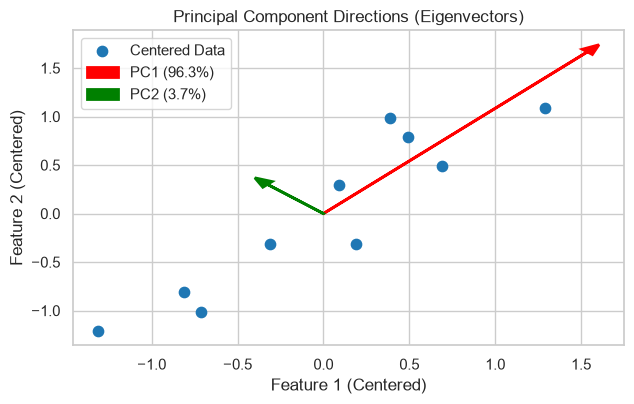

In [3]:
# Step 4: Project data onto top eigenvector (PC1)
pc1 = eigen_vecs[:, 0:1]
X_projected = np.dot(X_centered, pc1)

print("Projected 1D Data Shape:", X_projected.shape)
print("First 5 Projected Values:\n", X_projected[:5].round(3))

# Plot Principal Component Axes
plt.figure(figsize=(6.5, 4.2))
plt.scatter(X_centered[:, 0], X_centered[:, 1], color="#1f77b4", s=55, label="Centered Data")
for i in range(2):
    vec = eigen_vecs[:, i] * np.sqrt(eigen_vals[i]) * 2
    color = 'red' if i == 0 else 'green'
    plt.arrow(0, 0, vec[0], vec[1], head_width=0.08, head_length=0.1, fc=color, ec=color, linewidth=2, label=f"PC{i+1} ({explained_ratio[i]:.1f}%)")

plt.title("Principal Component Directions (Eigenvectors)")
plt.xlabel("Feature 1 (Centered)")
plt.ylabel("Feature 2 (Centered)")
plt.legend()
plt.tight_layout()
plt.show()
